In [3]:

# Part 1: Import Required Libraries

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import joblib

print("All libraries imported successfully!")


All libraries imported successfully!


In [4]:

# Part 2: Load Dataset

files = glob.glob("/kaggle/input/**/*.csv", recursive=True)

print("Available CSV files:")

for file in files:
    print(file)

if not files:
    print("No CSV file found. Please attach your dataset.")

else:
    df = pd.read_csv(files[0])

    print("\nDataset loaded successfully!")
    print("Dataset shape:", df.shape)

    display(df.head())


Available CSV files:
/kaggle/input/datasets/fatemaaktherpromy/codealpha-car-price-prediction/archive (3)/car data.csv

Dataset loaded successfully!
Dataset shape: (301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [5]:

# Part 3: Data Cleaning

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Clean column names
df.columns = df.columns.str.strip()

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDataset information:")
df.info()


Dataset shape: (299, 9)

Column names:
['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Driven_kms', 'Fuel_Type', 'Selling_type', 'Transmission', 'Owner']

Missing values:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Driven_kms       0
Fuel_Type        0
Selling_type     0
Transmission     0
Owner            0
dtype: int64

Dataset information:
<class 'pandas.core.frame.DataFrame'>
Index: 299 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       299 non-null    object 
 1   Year           299 non-null    int64  
 2   Selling_Price  299 non-null    float64
 3   Present_Price  299 non-null    float64
 4   Driven_kms     299 non-null    int64  
 5   Fuel_Type      299 non-null    object 
 6   Selling_type   299 non-null    object 
 7   Transmission   299 non-null    object 
 8   Owner          299 non-null    int64  
dtypes: float64(2), int64(3), ob

In [6]:

# Part 4: Identify Target Column

target_options = [
    "Selling_Price",
    "selling_price",
    "Price",
    "price",
    "Selling Price",
    "SellingPrice"
]

target = next(
    (col for col in target_options if col in df.columns),
    None
)

print("Target column:", target)

if target is None:
    print("Price column not found!")
    print("Available columns:", df.columns.tolist())


Target column: Selling_Price


In [7]:

# Part 5: Prepare Data

if target is None:
    raise ValueError("Please set target to your dataset's actual price column.")

# Convert price to numeric
df[target] = pd.to_numeric(df[target], errors="coerce")

# Remove rows without a valid target price
df = df.dropna(subset=[target])
df = df[df[target] >= 0].copy()

# Create car age if a year column exists
year_options = ["Year", "year", "Model_Year", "model_year"]

year_col = next(
    (col for col in year_options if col in df.columns),
    None
)

if year_col:
    df[year_col] = pd.to_numeric(df[year_col], errors="coerce")
    df["Car_Age"] = 2026 - df[year_col]
    df.loc[df["Car_Age"] < 0, "Car_Age"] = np.nan

# Remove target and identifier/name columns from features
exclude_cols = [
    target, "Car_Name", "car_name", "Name", "name",
    "Car_ID", "car_id", "ID", "id",
    "Year", "year", "Model_Year", "model_year"
]

X = df.drop(
    columns=[col for col in exclude_cols if col in df.columns]
).copy()

X = X.dropna(axis=1, how="all")
X = X.select_dtypes(include=["number", "object", "category", "bool"])
y = df.loc[X.index, target]

print("Features:", X.columns.tolist())
print("Target:", target)
print("X shape:", X.shape)
print("y shape:", y.shape)

display(X.head())


Features: ['Present_Price', 'Driven_kms', 'Fuel_Type', 'Selling_type', 'Transmission', 'Owner', 'Car_Age']
Target: Selling_Price
X shape: (299, 7)
y shape: (299,)


,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner,Car_Age
0,5.59,27000,Petrol,Dealer,Manual,0,12.0
1,9.54,43000,Diesel,Dealer,Manual,0,13.0
2,9.85,6900,Petrol,Dealer,Manual,0,9.0
3,4.15,5200,Petrol,Dealer,Manual,0,15.0
4,6.87,42450,Diesel,Dealer,Manual,0,12.0


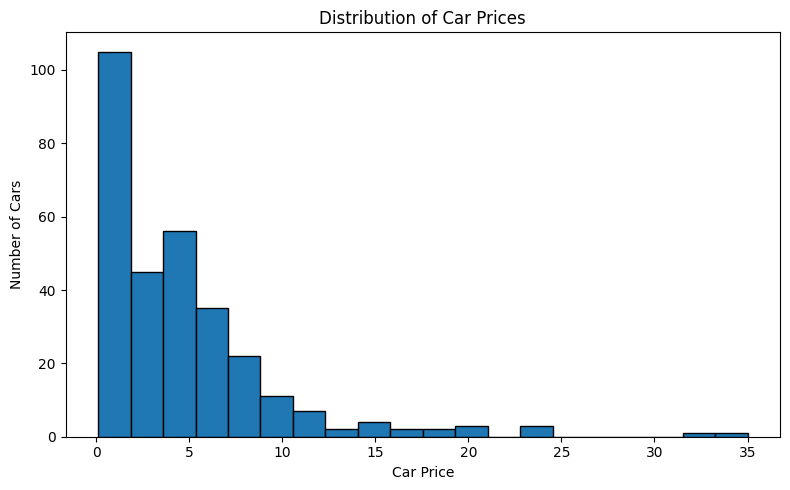

In [8]:

# Part 6: Price Distribution

plt.figure(figsize=(8, 5))
plt.hist(y, bins=20, edgecolor="black")

plt.title("Distribution of Car Prices")
plt.xlabel("Car Price")
plt.ylabel("Number of Cars")

plt.tight_layout()
plt.show()


In [9]:

# Part 7: Identify Feature Types

numeric_features = X.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)


Numerical features:
['Present_Price', 'Driven_kms', 'Owner', 'Car_Age']

Categorical features:
['Fuel_Type', 'Selling_type', 'Transmission']


In [10]:

# Part 8: Handle Missing Values and Encode Categories

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

transformers = []

if numeric_features:
    transformers.append(
        ("numeric", numeric_pipeline, numeric_features)
    )

if categorical_features:
    transformers.append(
        ("categorical", categorical_pipeline, categorical_features)
    )

preprocessor = ColumnTransformer(transformers=transformers)

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


In [11]:

# Part 9: Split Dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 239
Testing samples: 60


In [12]:

# Part 10: Train Random Forest Regressor

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

print("Model training completed successfully!")


Model training completed successfully!


In [13]:

# Part 11: Model Evaluation

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("===== Model Evaluation =====")
print(f"Mean Absolute Error (MAE): {mae:.3f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.3f}")
print(f"R2 Score: {r2:.3f}")


===== Model Evaluation =====
Mean Absolute Error (MAE): 1.560
Root Mean Squared Error (RMSE): 3.790
R2 Score: 0.443


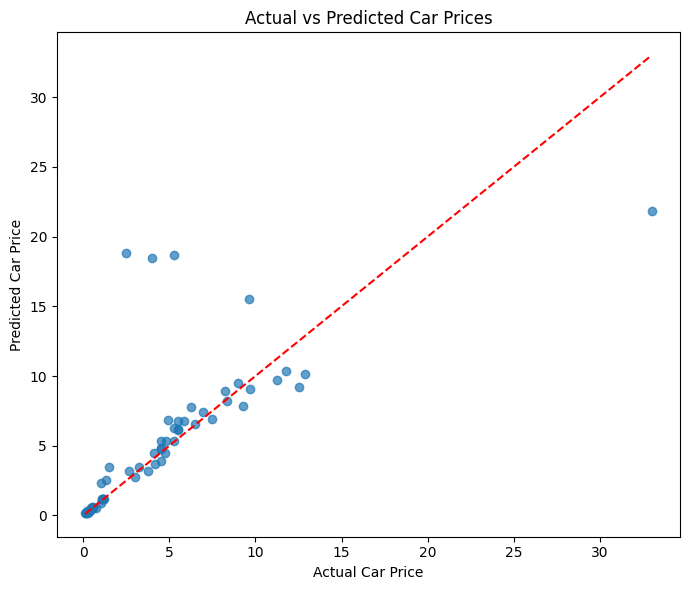

In [14]:

# Part 12: Visualize Predictions

plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())

plt.plot([low, high], [low, high], "r--")

plt.xlabel("Actual Car Price")
plt.ylabel("Predicted Car Price")
plt.title("Actual vs Predicted Car Prices")

plt.tight_layout()
plt.show()


In [15]:

# Part 13: Save Model

joblib.dump(model, "car_price_prediction_model.pkl")

print("Model saved successfully!")


Model saved successfully!


In [16]:

# Part 14: Predict Price for a Test Car

sample_car = X_test.iloc[[0]]

predicted_price = model.predict(sample_car)[0]
actual_price = y_test.iloc[0]

print("Sample car features:")
display(sample_car)

print(f"Predicted price: {predicted_price:.2f}")
print(f"Actual price: {actual_price:.2f}")


Sample car features:


,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner,Car_Age
283,11.8,9010,Petrol,Dealer,Manual,0,10.0


Predicted price: 9.52
Actual price: 8.99
